# ИДЗ №1: Эмпирический и теоретический анализ алгоритмов сортировки
**Вариант:** Selection Sort (Сортировка выбором), Bubble Sort с флагом оптимизации (Сортировка пузырьком), LSD Radix Sort (Поразрядная сортировка)
**ФИО**: Боровкова Есения Александровна
**Группа:** Б06-507

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import random
import time
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

print("Библиотеки успешно загружены! Можно писать сортировки.")

Библиотеки успешно загружены! Можно писать сортировки.


In [3]:
!pip install matplotlib numpy scipy

In [12]:
def selection_sort(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    """
    Сортировка выбором (Selection Sort).
    
    Сложность:
        - По времени: O(N^2) во всех случаях (best, average, worst).
        - По памяти: O(1) (in-place, дополнительная память не требуется).
        
    Возвращает: (отсортированный массив, число сравнений, число перестановок).
    """
    a = arr.copy()
    comparisons = 0
    swaps = 0
    n = len(a)
    for i in range(n - 1):
        min_idx = i
        for j in range(i + 1, n):
            comparisons += 1
            if a[j] < a[min_idx]:
                min_idx = j
        if min_idx != i:
            a[i], a[min_idx] = a[min_idx], a[i]
            swaps += 1
    return a, comparisons, swaps


def bubble_sort(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    """
    Пузырьковая сортировка с флагом (Bubble Sort).
    
    Сложность:
        - По времени: O(N^2) в худшем и среднем случаях, O(N) в лучшем (на отсортированных данных).
        - По памяти: O(1) (in-place).
        
    Возвращает: (отсортированный массив, число сравнений, число перестановок).
    """
    a = arr.copy()
    comparisons = 0
    swaps = 0
    n = len(a)
    for i in range(n - 1):
        swapped = False
        for j in range(n - 1 - i):
            comparisons += 1
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swaps += 1
                swapped = True
        if not swapped:
            break
    return a, comparisons, swaps


def radix_sort_lsd(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    """
    Поразрядная сортировка LSD (Radix Sort).
    
    Сложность:
        - По времени: O(d * (N + k)), где d - число разрядов, k - основание (10).
        - По памяти: O(N + k) для хранения корзин (buckets).
        
    Возвращает: (отсортированный массив, число сравнений, число записей).
    """
    a = arr.copy()
    comparisons = 0
    writes = 0
    if not a:
        return a, comparisons, writes
    
    max_val = max(a)
    exp = 1
    while max_val // exp > 0:
        buckets = [[] for _ in range(10)]
        for x in a:
            digit = (int(x) // exp) % 10  # int(x) на случай float
            buckets[digit].append(x)
            writes += 1
        a = [x for bucket in buckets for x in bucket]
        writes += len(a)
        exp *= 10
    return a, comparisons, writes

In [13]:
# Тестирование на простых массивах
test_arr = [5, 2, 9, 1, 5, 6]

print("Исходный:", test_arr)
print("Selection:", selection_sort(test_arr)[0])
print("Bubble:   ", bubble_sort(test_arr)[0])
print("Radix:    ", radix_sort_lsd(test_arr)[0])

# Проверка на пустом массиве и массиве из одного элемента
assert selection_sort([])[0] == []
assert bubble_sort([1])[0] == [1]
assert radix_sort_lsd([10, 10, 10])[0] == [10, 10, 10]

print("\nВсе тесты пройдены успешно!")

Исходный: [5, 2, 9, 1, 5, 6]
Selection: [1, 2, 5, 5, 6, 9]
Bubble:    [1, 2, 5, 5, 6, 9]
Radix:     [1, 2, 5, 5, 6, 9]

Все тесты пройдены успешно!


In [14]:
# Функция для генерации данных разных типов
def generate_data(n, kind, seed=0):
    rng = random.Random(seed)
    if kind == "random":
        return [rng.randint(0, 10**6) for _ in range(n)]
    if kind == "sorted":
        return list(range(n))
    if kind == "reversed":
        return list(range(n, 0, -1))
    if kind == "nearly_sorted":
        a = list(range(n))
        for _ in range(max(1, int(n * 0.05))):
            i, j = rng.randrange(n), rng.randrange(n)
            a[i], a[j] = a[j], a[i]
        return a
    if kind == "duplicates":
        return [rng.randint(1, 5) for _ in range(n)]
    raise ValueError(kind)

# Функция для замера времени
def benchmark(sort_fn, sizes, kinds, repeats=3):
    results = {}
    for kind in kinds:
        for n in sizes:
            times = []
            for r in range(repeats):
                data = generate_data(n, kind, seed=r)
                t0 = time.perf_counter()
                sort_fn(data)
                t1 = time.perf_counter()
                times.append(t1 - t0)
            mean_t = sum(times) / len(times)
            results[(kind, n)] = {"mean_time": mean_t}
    return results

print("Функции для замеров готовы!")

Функции для замеров готовы!


In [15]:
# 1. Замеры для квадратичных сортировок (Selection и Bubble)
sizes_slow = [100, 300, 600, 1000, 2000]
kinds = ["random", "sorted", "reversed"]

print("Замеряю Selection Sort...")
res_sel = benchmark(selection_sort, sizes_slow, kinds, repeats=3)

print("Замеряю Bubble Sort...")
res_bub = benchmark(bubble_sort, sizes_slow, kinds, repeats=3)

print("Готово!")

Замеряю Selection Sort...
Замеряю Bubble Sort...
Готово!


In [16]:
# 2. Замеры для быстрой сортировки Radix
sizes_fast = [1000, 5000, 10000, 50000, 100000]

print("Замеряю Radix Sort...")
res_radix = benchmark(radix_sort_lsd, sizes_fast, kinds, repeats=3)

print("Готово!")

Замеряю Radix Sort...
Готово!


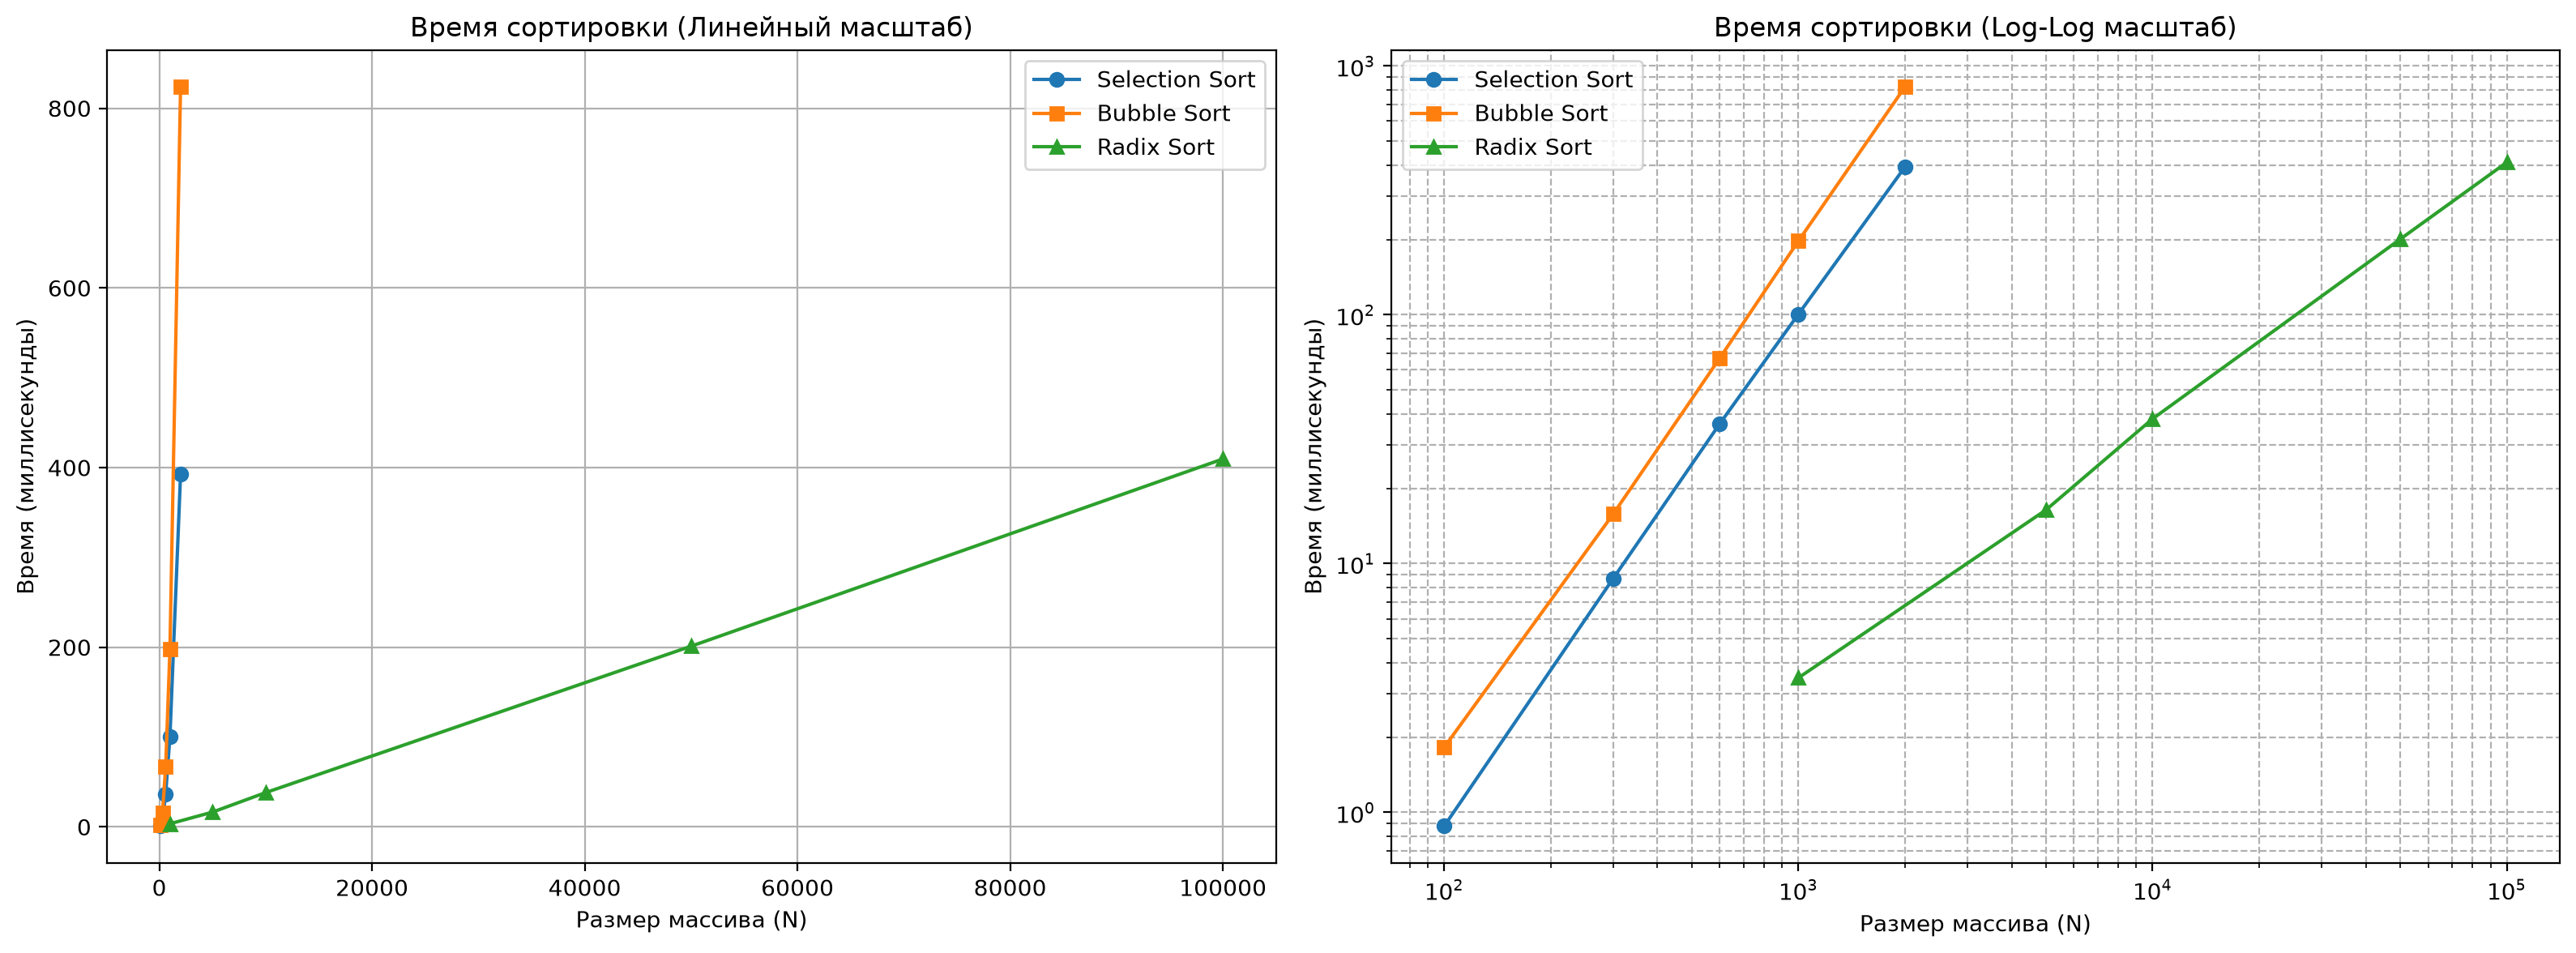

In [17]:
import matplotlib.pyplot as plt

# Создаем фигуру с двумя графиками рядом
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1. Линейный масштаб
ax1 = axes[0]
# Берем данные для случайных массивов (random)
y_sel = [res_sel[("random", n)]["mean_time"] * 1000 for n in sizes_slow] # в миллисекундах
y_bub = [res_bub[("random", n)]["mean_time"] * 1000 for n in sizes_slow]
y_rad = [res_radix[("random", n)]["mean_time"] * 1000 for n in sizes_fast]

ax1.plot(sizes_slow, y_sel, marker='o', label='Selection Sort')
ax1.plot(sizes_slow, y_bub, marker='s', label='Bubble Sort')
ax1.plot(sizes_fast, y_rad, marker='^', label='Radix Sort')

ax1.set_title("Время сортировки (Линейный масштаб)")
ax1.set_xlabel("Размер массива (N)")
ax1.set_ylabel("Время (миллисекунды)")
ax1.grid(True)
ax1.legend()


# График 2. Логарифмический масштаб (Log-Log) 
ax2 = axes[1]

ax2.plot(sizes_slow, y_sel, marker='o', label='Selection Sort')
ax2.plot(sizes_slow, y_bub, marker='s', label='Bubble Sort')
ax2.plot(sizes_fast, y_rad, marker='^', label='Radix Sort')

# Включаем логарифмические шкалы по обеим осям
ax2.set_xscale('log')
ax2.set_yscale('log')

ax2.set_title("Время сортировки (Log-Log масштаб)")
ax2.set_xlabel("Размер массива (N)")
ax2.set_ylabel("Время (миллисекунды)")
ax2.grid(True, which="both", ls="--")
ax2.legend()

plt.tight_layout()
plt.show()

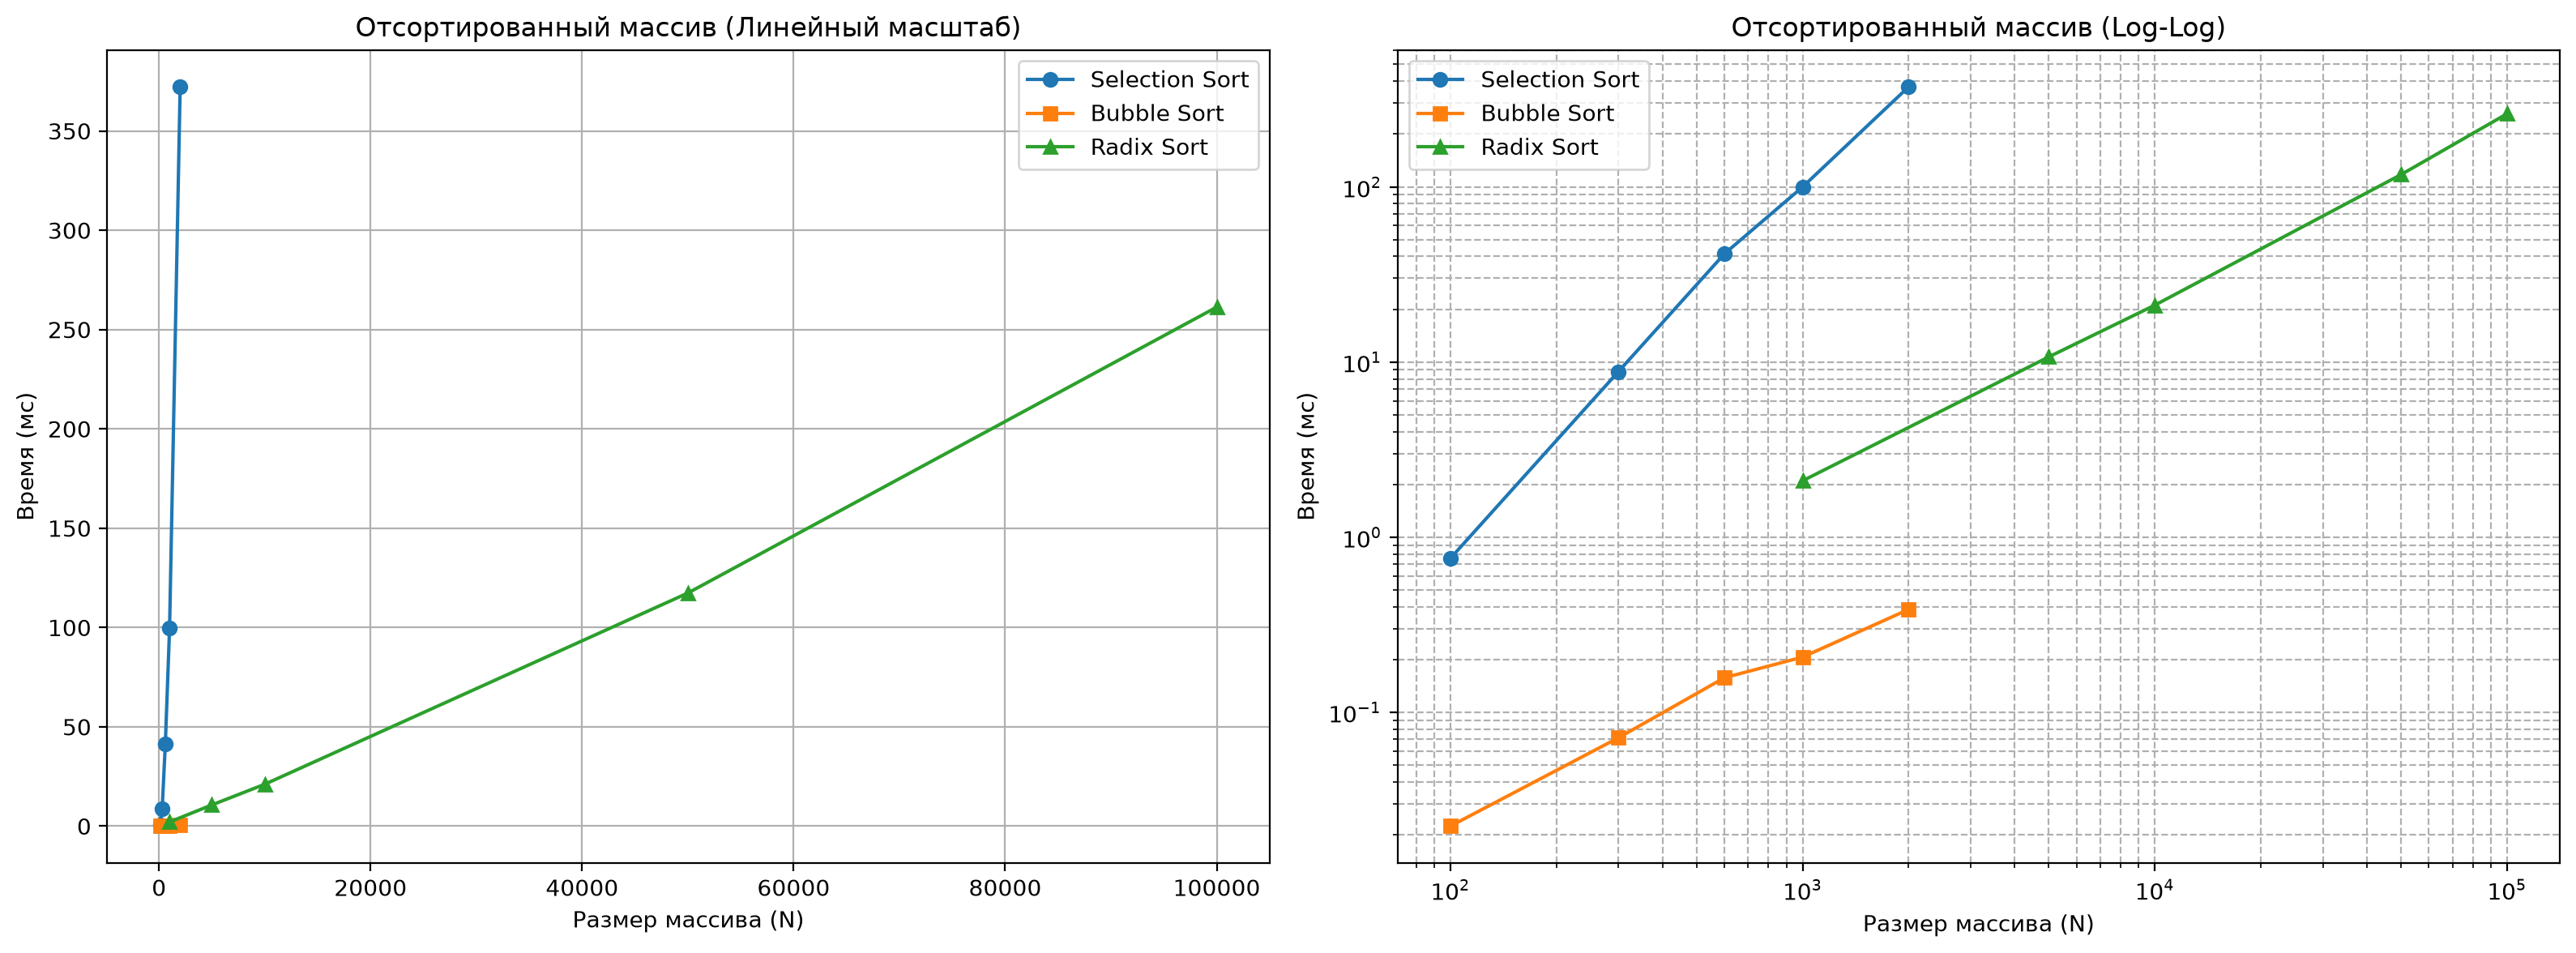

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Берем данные для уже отсортированных массивов массивов ("sorted")
y_sel_s = [res_sel[("sorted", n)]["mean_time"] * 1000 for n in sizes_slow]
y_bub_s = [res_bub[("sorted", n)]["mean_time"] * 1000 for n in sizes_slow]
y_rad_s = [res_radix[("sorted", n)]["mean_time"] * 1000 for n in sizes_fast]

# Линейный
ax1 = axes[0]
ax1.plot(sizes_slow, y_sel_s, marker='o', label='Selection Sort')
ax1.plot(sizes_slow, y_bub_s, marker='s', label='Bubble Sort')
ax1.plot(sizes_fast, y_rad_s, marker='^', label='Radix Sort')
ax1.set_title("Отсортированный массив (Линейный масштаб)")
ax1.set_xlabel("Размер массива (N)")
ax1.set_ylabel("Время (мс)")
ax1.grid(True)
ax1.legend()

# Log-Log
ax2 = axes[1]
ax2.plot(sizes_slow, y_sel_s, marker='o', label='Selection Sort')
ax2.plot(sizes_slow, y_bub_s, marker='s', label='Bubble Sort')
ax2.plot(sizes_fast, y_rad_s, marker='^', label='Radix Sort')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_title("Отсортированный массив (Log-Log)")
ax2.set_xlabel("Размер массива (N)")
ax2.set_ylabel("Время (мс)")
ax2.grid(True, which="both", ls="--")
ax2.legend()

plt.tight_layout()
plt.show()

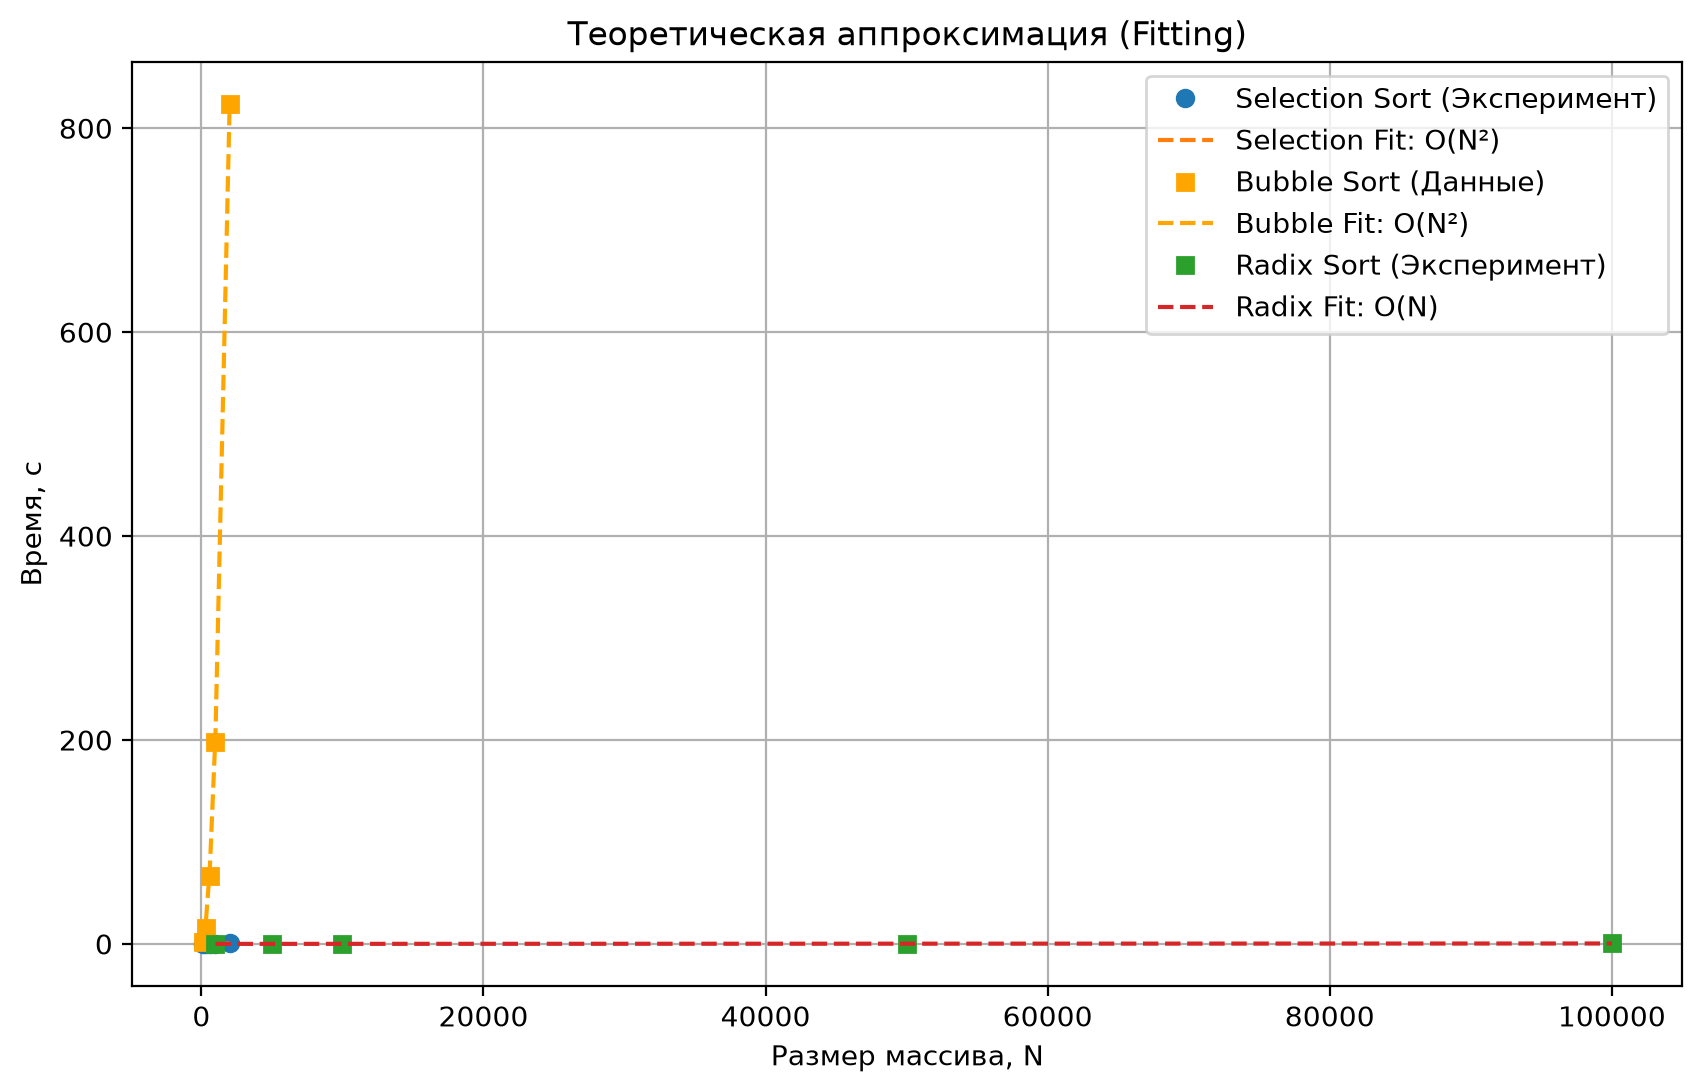

In [21]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

# Модели (функции) для подгонки
def quad_model(n, c): return c * n**2
def lin_model(n, c): return c * n

# Берем данные для Selection и Radix на случайных данных
x_slow = np.array(sizes_slow)
y_sel = np.array([res_sel[("random", n)]["mean_time"] for n in sizes_slow])

x_fast = np.array(sizes_fast)
y_rad = np.array([res_radix[("random", n)]["mean_time"] for n in sizes_fast])

# Подбираем коэффициенты 
popt_sel, _ = curve_fit(quad_model, x_slow, y_sel)
popt_rad, _ = curve_fit(lin_model, x_fast, y_rad)
popt_bub, _ = curve_fit(quad_model, x_slow, y_bub)

# Строим график
plt.figure(figsize=(10, 6))

# Selection: точки + теоретическая кривая O(N^2)
plt.plot(x_slow, y_sel, 'o', label='Selection Sort (Эксперимент)')
plt.plot(x_slow, quad_model(x_slow, *popt_sel), '--', label=f'Selection Fit: O(N²)')

# Bubble 
plt.plot(x_slow, y_bub, 's', color='orange', label='Bubble Sort (Данные)')
plt.plot(x_slow, quad_model(x_slow, *popt_bub), '--', color='orange', label='Bubble Fit: O(N²)')


# Radix: точки + теоретическая кривая O(N)
plt.plot(x_fast, y_rad, 's', label='Radix Sort (Эксперимент)')
plt.plot(x_fast, lin_model(x_fast, *popt_rad), '--', label=f'Radix Fit: O(N)')

plt.title("Теоретическая аппроксимация (Fitting)")
plt.xlabel("Размер массива, N")
plt.ylabel("Время, с")
plt.legend()
plt.grid(True)
plt.show()

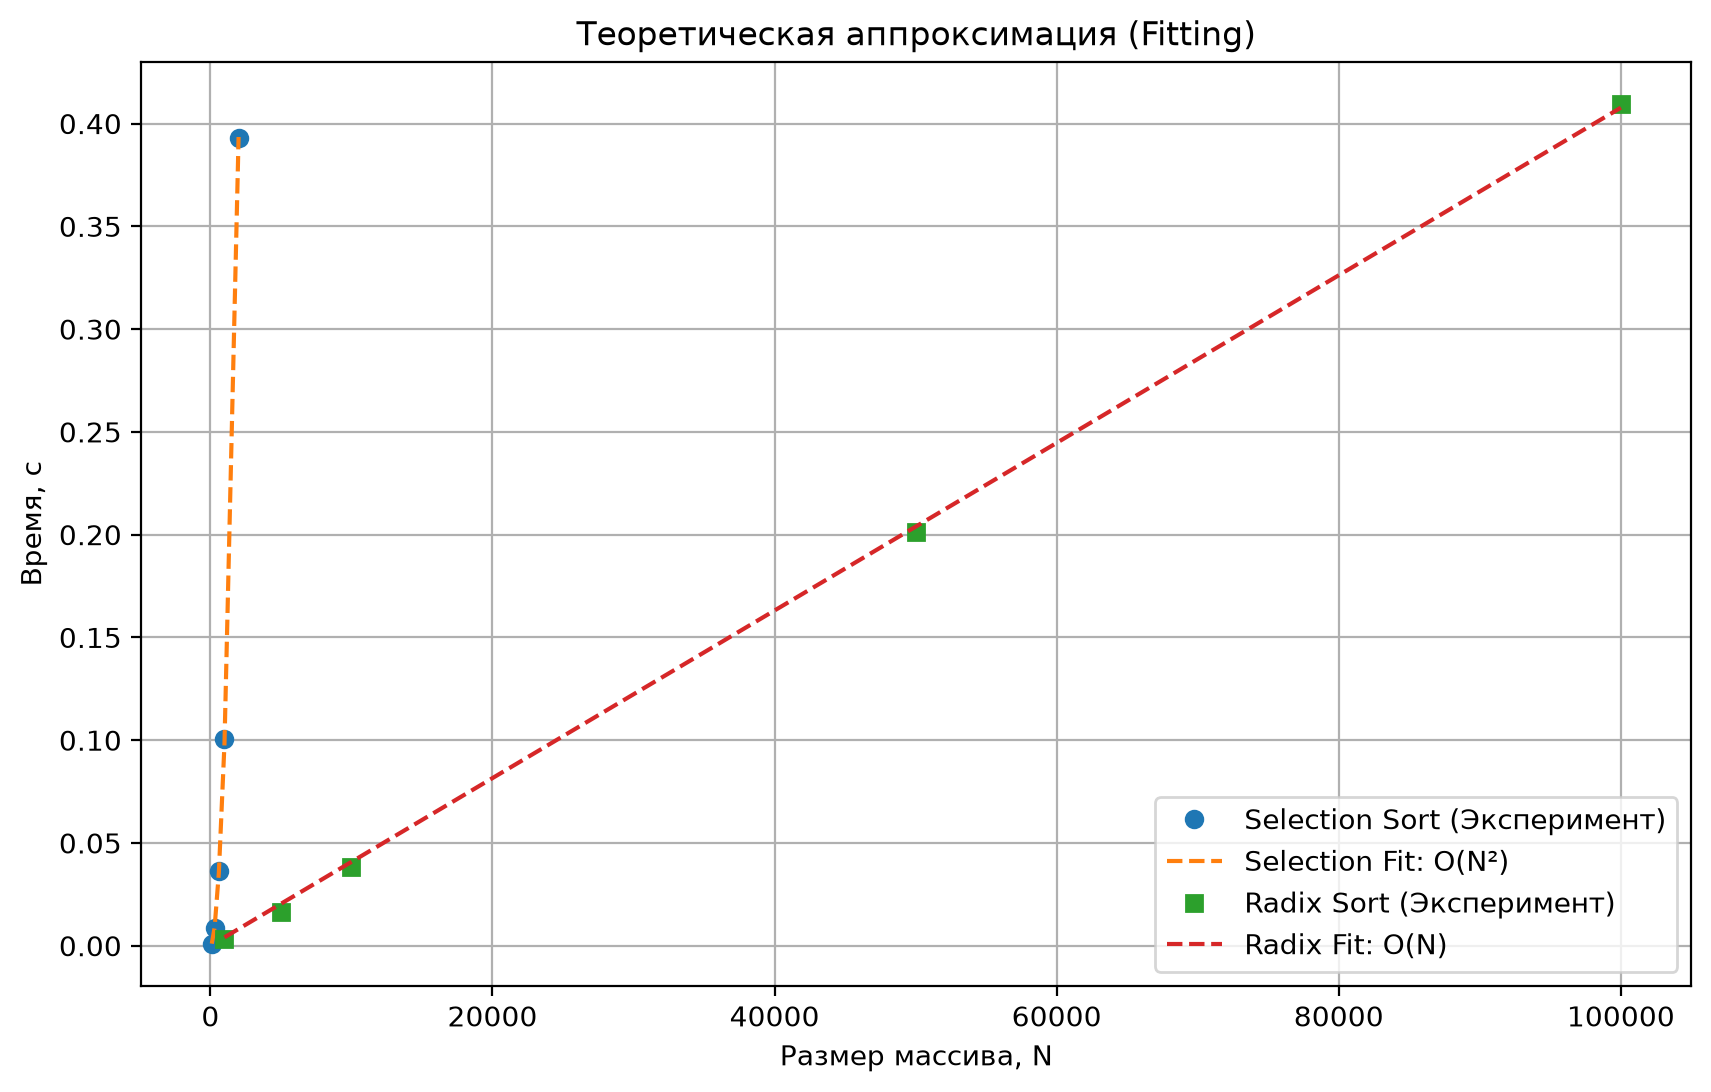

In [22]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

# Модели (функции) для подгонки
def quad_model(n, c): return c * n**2
def lin_model(n, c): return c * n

# Берем данные для Selection и Radix на случайных данных
x_slow = np.array(sizes_slow)
y_sel = np.array([res_sel[("random", n)]["mean_time"] for n in sizes_slow])

x_fast = np.array(sizes_fast)
y_rad = np.array([res_radix[("random", n)]["mean_time"] for n in sizes_fast])

# Подбираем коэффициенты 
popt_sel, _ = curve_fit(quad_model, x_slow, y_sel)
popt_rad, _ = curve_fit(lin_model, x_fast, y_rad)
#popt_bub, _ = curve_fit(quad_model, x_slow, y_bub)

# Строим график
plt.figure(figsize=(10, 6))

# Selection: точки + теоретическая кривая O(N^2)
plt.plot(x_slow, y_sel, 'o', label='Selection Sort (Эксперимент)')
plt.plot(x_slow, quad_model(x_slow, *popt_sel), '--', label=f'Selection Fit: O(N²)')

#Bubble 
#plt.plot(x_slow, y_bub, 's', color='orange', label='Bubble Sort (Данные)')
#plt.plot(x_slow, quad_model(x_slow, *popt_bub), '--', color='orange', label='Bubble Fit: O(N²)')

# Radix: точки + теоретическая кривая O(N)
plt.plot(x_fast, y_rad, 's', label='Radix Sort (Эксперимент)')
plt.plot(x_fast, lin_model(x_fast, *popt_rad), '--', label=f'Radix Fit: O(N)')

plt.title("Теоретическая аппроксимация (Fitting)")
plt.xlabel("Размер массива, N")
plt.ylabel("Время, с")
plt.legend()
plt.grid(True)
plt.show()

## Аналитический вывод

1. **Почему на почти отсортированных данных победил конкретный алгоритм?**
На графиках для отсортированного массива видно, что Bubble Sort с флагом работает быстрее всех. Это происходит потому, что флаг `swapped` позволяет алгоритму понять, что массив уже отсортирован, и завершить работу после первого прохода за O(N). Selection Sort так не умеет — он всегда делает N²/2 сравнений независимо от данных.

2. **Какой алгоритм показал наименьшее число сравнений?**
Radix Sort, так как он вообще не использует сравнения элементов между собой (он некомпараторный, сортирует по разрядам). Среди компараторных алгоритмов меньше всего сравнений у Bubble Sort на отсортированных данных.

3. **Подтвердился ли теоретический порядок сложности на Log-Log?**
Да, полностью. На логарифмических графиках наклон прямых для Selection и Bubble (на случайных данных) соответствует O(N²) — линии идут круто вверх. Линия Radix Sort имеет гораздо меньший наклон, что подтверждает его линейную сложность O(N).